<a href="https://colab.research.google.com/github/Oyakata32/Lesson-20/blob/main/lesson_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Dane ===
Liczba obserwacji: 50
X: zakres [0.0, 10.0]
y: zakres [5.1, 26.3]

=== Wyuczone parametry ===
Wyraz wolny (intercept): w₀ = 5.1289 (prawdziwy: 5)
Nachylenie (slope): w₁ = 1.8840 (prawdziwy: 2)


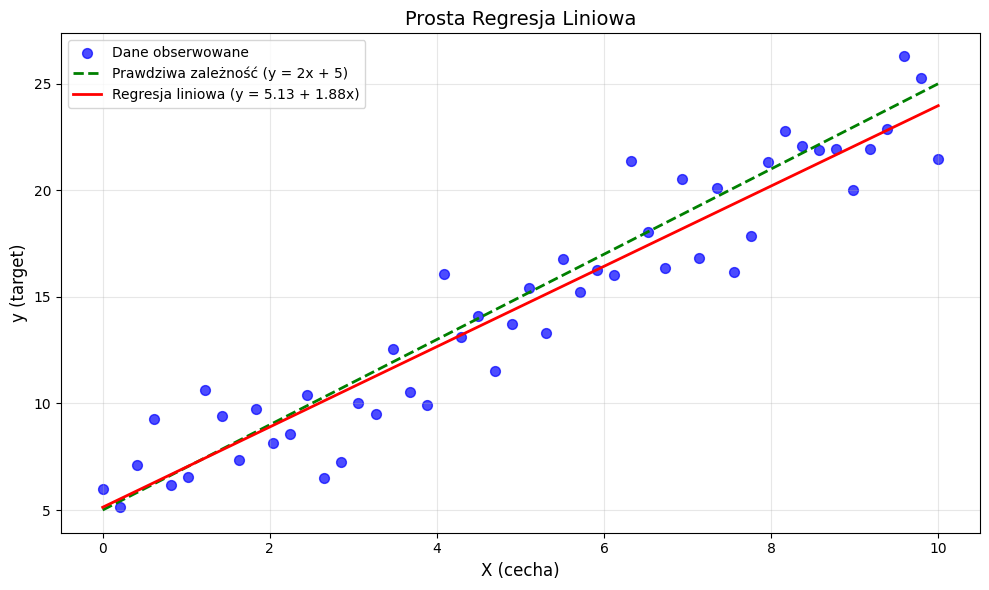

'Generuje 50 punktów z zależnością y = 2x + 5 i losowym szumem. Następnie oblicza ręcznie nachylenie prostej oraz wyraz wolny metodą najmniejszych kwadratów (OLS), wyznacza predykcje i rysuje porównanie z zależnością rzeczywistą.'

In [2]:
# Prosta regresja liniowa od podstaw
import numpy as np
import matplotlib.pyplot as plt
# Generowanie prostych danych
np.random.seed(42)
X = np.linspace(0, 10, 50)  # 50 punktów od 0 do 10
y_true = 2 * X + 5  # Prawdziwa zależność: y = 2x + 5
noise = np.random.normal(0, 2, size=X.shape)  # Szum
y = y_true + noise  # Obserwowane dane
print("=== Dane ===")
print(f"Liczba obserwacji: {len(X)}")
print(f"X: zakres [{X.min():.1f}, {X.max():.1f}]")
print(f"y: zakres [{y.min():.1f}, {y.max():.1f}]")
# Rozwiązanie analityczne (Ordinary Least Squares)
# w₁ = Σ(x - x̄)(y - ȳ) / Σ(x - x̄)²
# w₀ = ȳ - w₁x̄
x_mean = X.mean()
y_mean = y.mean()
# Obliczenie współczynnika nachylenia (slope)
numerator = np.sum((X - x_mean) * (y - y_mean))
denominator = np.sum((X - x_mean) ** 2)
w1 = numerator / denominator
# Obliczenie wyrazu wolnego (intercept)
w0 = y_mean - w1 * x_mean
print(f"\n=== Wyuczone parametry ===")
print(f"Wyraz wolny (intercept): w₀ = {w0:.4f} (prawdziwy: 5)")
print(f"Nachylenie (slope): w₁ = {w1:.4f} (prawdziwy: 2)")
# Predykcja
y_pred = w0 + w1 * X
# Wizualizacja
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.7, label='Dane obserwowane', color='blue', s=50)
plt.plot(X, y_true, 'g--', label='Prawdziwa zależność (y = 2x + 5)', linewidth=2)
plt.plot(X, y_pred, 'r-', label=f'Regresja liniowa (y = {w0:.2f} + {w1:.2f}x)',
linewidth=2)
plt.xlabel('X (cecha)', fontsize=12)
plt.ylabel('y (target)', fontsize=12)
plt.title('Prosta Regresja Liniowa', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Regresja liniowa używając scikit-learn

"""Generuje 50 punktów z zależnością y = 2x + 5 i losowym szumem. Następnie oblicza ręcznie nachylenie prostej oraz wyraz wolny metodą najmniejszych kwadratów (OLS), wyznacza predykcje i rysuje porównanie z zależnością rzeczywistą."""

Rozmiar zbioru treningowego: 80
Rozmiar zbioru testowego: 20

=== Parametry modelu ===
Wyraz wolny (intercept_): 7.2858
Współczynnik (coef_): 2.9197

=== Metryki ===
Train MSE: 3.3907
Test MSE: 2.6148
Train R²: 0.9552
Test R²: 0.9686


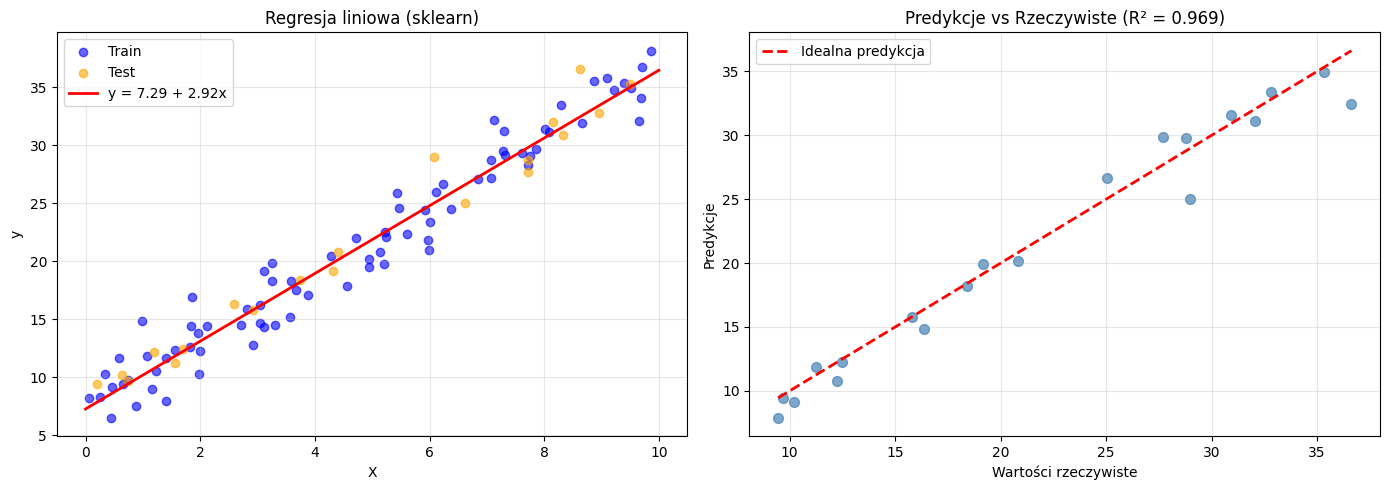

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
# Generowanie danych
np.random.seed(42)
X = np.random.rand(100, 1) * 10  # 100 obserwacji, 1 cecha
y = 3 * X.flatten() + 7 + np.random.randn(100) * 2  # y = 3x + 7 + szum
# Podział na train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Rozmiar zbioru treningowego: {len(X_train)}")
print(f"Rozmiar zbioru testowego: {len(X_test)}")
# Tworzenie i trening modelu
model = LinearRegression()
model.fit(X_train, y_train)
# Wyuczone parametry
print(f"\n=== Parametry modelu ===")
print(f"Wyraz wolny (intercept_): {model.intercept_:.4f}")
print(f"Współczynnik (coef_): {model.coef_[0]:.4f}")
# Predykcja
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
# Metryki
print(f"\n=== Metryki ===")
print(f"Train MSE: {mean_squared_error(y_train, y_pred_train):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_pred_test):.4f}")
print(f"Train R²: {r2_score(y_train, y_pred_train):.4f}")
print(f"Test R²: {r2_score(y_test, y_pred_test):.4f}")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Wykres 1: Dane i linia regresji
axes[0].scatter(X_train, y_train, alpha=0.6, label='Train', color='blue')
axes[0].scatter(X_test, y_test, alpha=0.6, label='Test', color='orange')
x_line = np.linspace(0, 10, 100).reshape(-1, 1)
axes[0].plot(x_line, model.predict(x_line), 'r-', linewidth=2,
             label=f'y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x')
axes[0].set_xlabel('X')
axes[0].set_ylabel('y')
axes[0].set_title('Regresja liniowa (sklearn)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Wykres 2: Predykcje vs Rzeczywiste
axes[1].scatter(y_test, y_pred_test, alpha=0.7, color='steelblue', s=50)
min_val, max_val = y_test.min(), y_test.max()
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2,
              label='Idealna predykcja')
axes[1].set_xlabel('Wartości rzeczywiste')
axes[1].set_ylabel('Predykcje')
axes[1].set_title(f'Predykcje vs Rzeczywiste (R² = {r2_score(y_test, y_pred_test):.3f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


=== California Housing Dataset ===
Liczba obserwacji: 20640
Liczba cech: 8

Cechy: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Podgląd danych:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

=== Model z oryginalnymi danymi ===
Intercept: -37.0233

Współczynniki:
  MedInc: 0.448675
  HouseAge: 0.009724
  AveRooms: -0.123323
  AveBedrms: 0.783145
  Population: -0.000002
  AveOccup: -0.003526
  Latitude: -0.419792
  Longitude: -0.433708

=== M

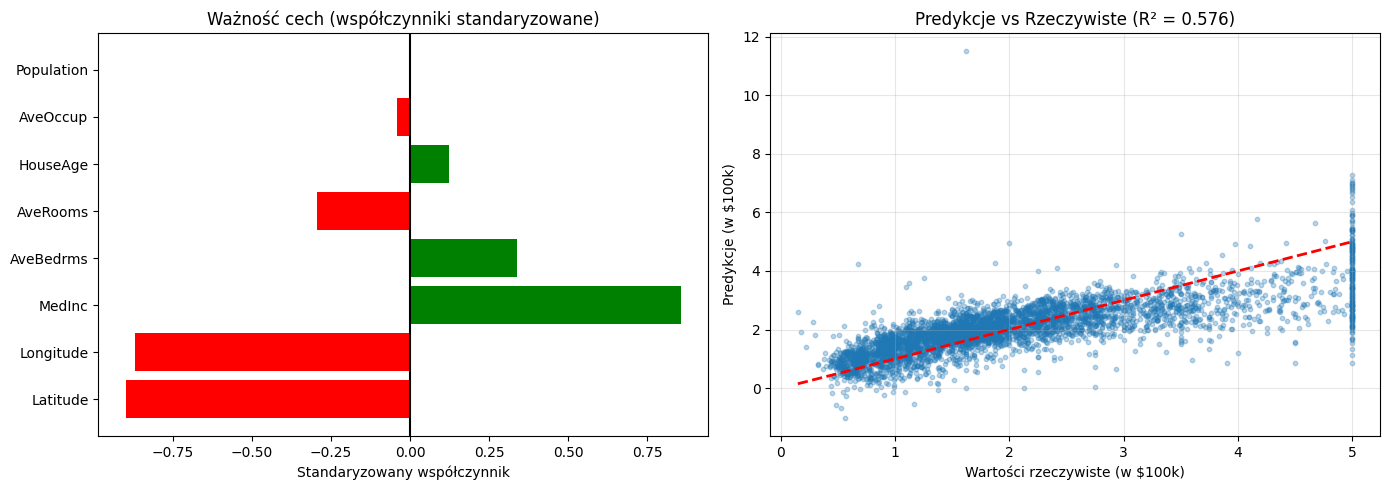

In [4]:
# Regresja wieloraka - wiele cech
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
# Wczytanie danych California Housing
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target
print("=== California Housing Dataset ===")
print(f"Liczba obserwacji: {len(y)}")
print(f"Liczba cech: {X.shape[1]}")
print(f"\nCechy: {list(X.columns)}")
print(f"\nPodgląd danych:")
print(X.head())
# Podział na train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Standaryzacja (ważna dla interpretacji!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Model bez standaryzacji (oryginalne współczynniki)
model_original = LinearRegression()
model_original.fit(X_train, y_train)
# Model ze standaryzacją (standaryzowane współczynniki)
model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)
# Wyniki
print("\n=== Model z oryginalnymi danymi ===")
print(f"Intercept: {model_original.intercept_:.4f}")
print("\nWspółczynniki:")
for name, coef in zip(X.columns, model_original.coef_):
    print(f"  {name}: {coef:.6f}")
print("\n=== Model ze standaryzowanymi danymi ===")
print(f"Intercept: {model_scaled.intercept_:.4f}")
print("\nStandaryzowane współczynniki (porównywalne między sobą):")
for name, coef in zip(X.columns, model_scaled.coef_):
    print(f"  {name}: {coef:.4f}")
# Predykcja i metryki
y_pred = model_original.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"\n=== Metryki (test) ===")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")
# Wizualizacja współczynników
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Współczynniki standaryzowane (można porównywać!)
sorted_idx = np.argsort(np.abs(model_scaled.coef_))[::-1]
colors = ['green' if c > 0 else 'red' for c in model_scaled.coef_[sorted_idx]]
axes[0].barh(np.array(X.columns)[sorted_idx], model_scaled.coef_[sorted_idx], color=colors)
axes[0].axvline(x=0, color='black', linestyle='-')
axes[0].set_xlabel('Standaryzowany współczynnik')
axes[0].set_title('Ważność cech (współczynniki standaryzowane)')
# Predykcje vs Rzeczywiste
axes[1].scatter(y_test, y_pred, alpha=0.3, s=10)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--',
linewidth=2)
axes[1].set_xlabel('Wartości rzeczywiste (w $100k)')
axes[1].set_ylabel('Predykcje (w $100k)')
axes[1].set_title(f'Predykcje vs Rzeczywiste (R² = {r2:.3f})')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
n = 500
# Cechy
advertising_budget = np.random.uniform(1000, 50000, n)  # Budżet reklamowy ($)
price = np.random.uniform(50, 200, n)  # Cena produktu ($)
competitor_price = np.random.uniform(40, 180, n)  # Cena konkurencji ($)
season = np.random.choice([0, 1, 2, 3], n)  # Sezon (0-3)
is_weekend = np.random.choice([0, 1], n)  # Czy weekend
# Target: sprzedaż (zależy od cech)
sales = (
    50000 +  # Bazowa sprzedaż
    0.8 * advertising_budget +  # Reklama zwiększa sprzedaż
    -200 * price +  # Wyższa cena = mniejsza sprzedaż
    150 * competitor_price +  # Wyższa cena konkurencji = większa sprzedaż
    5000 * (season == 3) +  # Sezon świąteczny
    3000 * is_weekend +  # Weekend
    np.random.randn(n) * 5000  # Szum
)
# Tworzenie DataFrame
df = pd.DataFrame({
    'advertising_budget': advertising_budget,
    'price': price,
    'competitor_price': competitor_price,
    'season_holiday': (season == 3).astype(int),
    'is_weekend': is_weekend,
    'sales': sales
})
print("=== Dane sprzedażowe ===")
print(df.describe())
# Przygotowanie danych
X = df.drop('sales', axis=1)
y = df['sales']
# Model z oryginalnymi danymi
model = LinearRegression()
model.fit(X, y)
print("\n=== Współczynniki modelu (oryginalne) ===")
print(f"Intercept: {model.intercept_:.2f}")
print("\nInterpretacja współczynników:")
interpretations = {
    'advertising_budget': f"{model.coef_[0]:.4f} → Każdy dodatkowy $1 na reklamę zwiększa sprzedaż o ${model.coef_[0]:.2f}",
    'price': f"{model.coef_[1]:.2f} → Wzrost ceny o $1 zmniejsza sprzedaż o ${abs(model.coef_[1]):.0f}",
    'competitor_price': f"{model.coef_[2]:.2f} → Wzrost ceny konkurencji o $1 zwiększa sprzedaż o ${model.coef_[2]:.0f}",
    'season_holiday': f"{model.coef_[3]:.2f} → Sezon świąteczny zwiększa sprzedaż o ${model.coef_[3]:.0f}",
    'is_weekend': f"{model.coef_[4]:.2f} → Weekend zwiększa sprzedaż o ${model.coef_[4]:.0f}"
}
for name, interp in interpretations.items():
    print(f"  {name}: {interp}")
# Standaryzowane współczynniki (do porównania ważności)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model_scaled = LinearRegression()
model_scaled.fit(X_scaled, y)
print("\n=== Standaryzowane współczynniki (porównanie ważności) ===")
importance = pd.DataFrame({
    'Feature': X.columns,
    'Standardized Coefficient': model_scaled.coef_,
    'Absolute Value': np.abs(model_scaled.coef_)
}).sort_values('Absolute Value', ascending=False)
print(importance.to_string(index=False))
print("\n→ Budżet reklamowy i cena mają największy wpływ na sprzedaż!")


=== Dane sprzedażowe ===
       advertising_budget       price  competitor_price  season_holiday  \
count          500.000000  500.000000        500.000000      500.000000   
mean         25411.997803  126.157368        109.678831        0.264000   
std          14538.017466   43.860062         40.816461        0.441241   
min           1531.044923   50.694803         40.691597        0.000000   
25%          12850.341496   86.920820         72.657917        0.000000   
50%          25660.561471  128.148735        110.936367        0.000000   
75%          37979.882005  164.411819        142.475856        1.000000   
max          49986.165991  199.690117        179.917922        1.000000   

       is_weekend          sales  
count  500.000000     500.000000  
mean     0.528000   64385.914540  
std      0.499715   16814.046930  
min      0.000000   13690.854257  
25%      0.000000   52034.037385  
50%      1.000000   64158.039423  
75%      1.000000   75617.058175  
max      1.000000  

=== Analiza współczynników regresji ===

   Feature  Coefficient  Std Error  t-statistic  p-value  CI Lower  CI Upper
    MedInc       0.4367     0.0042     104.0538   0.0000    0.4285    0.4449
  HouseAge       0.0094     0.0004      21.1432   0.0000    0.0086    0.0103
  AveRooms      -0.1073     0.0059     -18.2354   0.0000   -0.1189   -0.0958
 AveBedrms       0.6451     0.0281      22.9276   0.0000    0.5899    0.7002
Population      -0.0000     0.0000      -0.8373   0.4024   -0.0000    0.0000
  AveOccup      -0.0038     0.0005      -7.7686   0.0000   -0.0047   -0.0028
  Latitude      -0.4213     0.0072     -58.5414   0.0000   -0.4354   -0.4072
 Longitude      -0.4345     0.0075     -57.6822   0.0000   -0.4493   -0.4197

=== Istotność statystyczna (alpha = 0.05) ===
MedInc: p = 0.0000 ***
HouseAge: p = 0.0000 ***
AveRooms: p = 0.0000 ***
AveBedrms: p = 0.0000 ***
Population: p = 0.4024 ns
AveOccup: p = 0.0000 ***
Latitude: p = 0.0000 ***
Longitude: p = 0.0000 ***


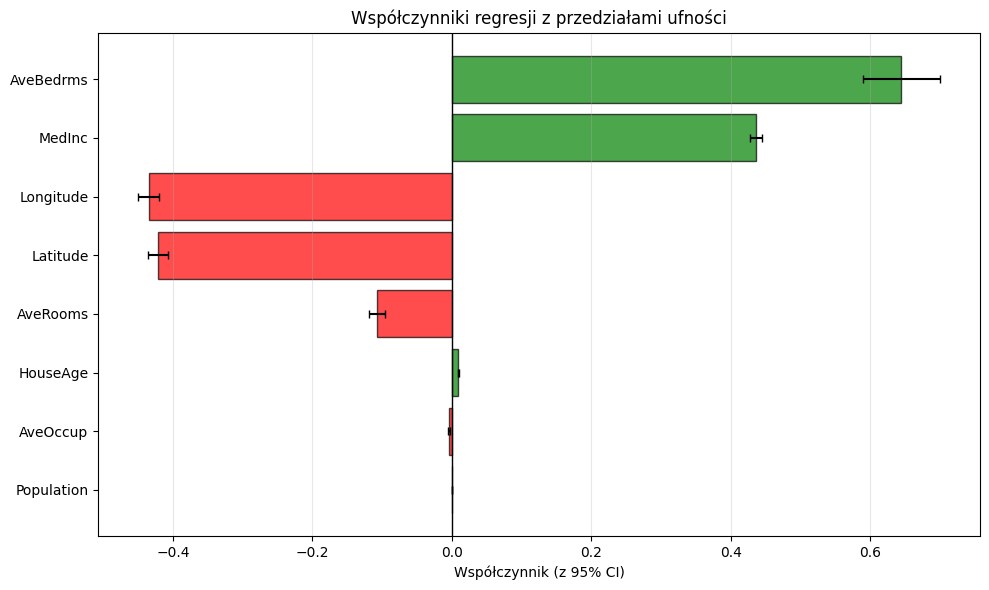

In [6]:
# Przedziały ufności dla współczynników
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
# Manualne funkcje statystyczne (z Lekcji 16):
# dla dużych n rozkład t-Studenta praktycznie równa się rozkładowi normalnemu,
# więc używamy normal_cdf / normal_ppf (California Housing: n ~ 20k, df >> 30)
def normal_cdf(x):
    """CDF rozkładu N(0,1) przez math.erf (Lekcja 16)."""
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))
# Dane
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target
# Model
model = LinearRegression()
model.fit(X, y)
# Obliczenie błędów standardowych współczynników
n = len(y)
p = X.shape[1]
y_pred = model.predict(X)
residuals = y - y_pred
# MSE residuów
mse_resid = np.sum(residuals**2) / (n - p - 1)
# Macierz (X'X)^(-1)
X_with_intercept = np.column_stack([np.ones(n), X])
XtX_inv = np.linalg.inv(X_with_intercept.T @ X_with_intercept)
# Błędy standardowe
se = np.sqrt(mse_resid * np.diag(XtX_inv))
se_coef = se[1:]  # Bez intercept
# t-statystyki i p-wartości (dla dużego n: t ≈ N(0,1))
t_stats = model.coef_ / se_coef
p_values = np.array([2 * (1 - normal_cdf(abs(t))) for t in t_stats])
# Przedziały ufności 95% — dla dużego n kwantyl 0.975 N(0,1) = 1.96
alpha = 0.05
z_critical = 1.96  # kwantyl 1 - alpha/2 dla N(0,1)
ci_lower = model.coef_ - z_critical * se_coef
ci_upper = model.coef_ + z_critical * se_coef
# Tabela wyników
results = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_,
    'Std Error': se_coef,
    't-statistic': t_stats,
    'p-value': p_values,
    'CI Lower': ci_lower,
    'CI Upper': ci_upper
})
print("=== Analiza współczynników regresji ===\n")
print(results.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
# Interpretacja istotności
print("\n=== Istotność statystyczna (alpha = 0.05) ===")
for _, row in results.iterrows():
    significance = ("***" if row['p-value'] < 0.001 else "**" if row['p-value'] < 0.01
                   else "*" if row['p-value'] < 0.05 else "ns")
    print(f"{row['Feature']}: p = {row['p-value']:.4f} {significance}")
# Wizualizacja
fig, ax = plt.subplots(figsize=(10, 6))
# Sortowanie po wartości bezwzględnej
sorted_idx = np.argsort(np.abs(model.coef_))
features_sorted = X.columns[sorted_idx]
coef_sorted = model.coef_[sorted_idx]
ci_lower_sorted = ci_lower[sorted_idx]
ci_upper_sorted = ci_upper[sorted_idx]
y_pos = np.arange(len(features_sorted))
colors = ['green' if c > 0 else 'red' for c in coef_sorted]
# Wykres z przedziałami ufności
ax.barh(y_pos, coef_sorted, color=colors, alpha=0.7, edgecolor='black')
ax.errorbar(coef_sorted, y_pos, xerr=[coef_sorted - ci_lower_sorted, ci_upper_sorted -
coef_sorted],
            fmt='none', color='black', capsize=3)
ax.axvline(x=0, color='black', linestyle='-', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(features_sorted)
ax.set_xlabel('Współczynnik (z 95% CI)')
ax.set_title('Współczynniki regresji z przedziałami ufności')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


=== Ceteris Paribus Analysis ===
Jak zmienia się predykcja gdy zmieniamy jedną cechę,
a pozostałe utrzymujemy na średnich wartościach?

Średnie wartości cech:
MedInc           3.870671
HouseAge        28.639486
AveRooms         5.429000
AveBedrms        1.096675
Population    1425.476744
AveOccup         3.070655
Latitude        35.631861
Longitude     -119.569704
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


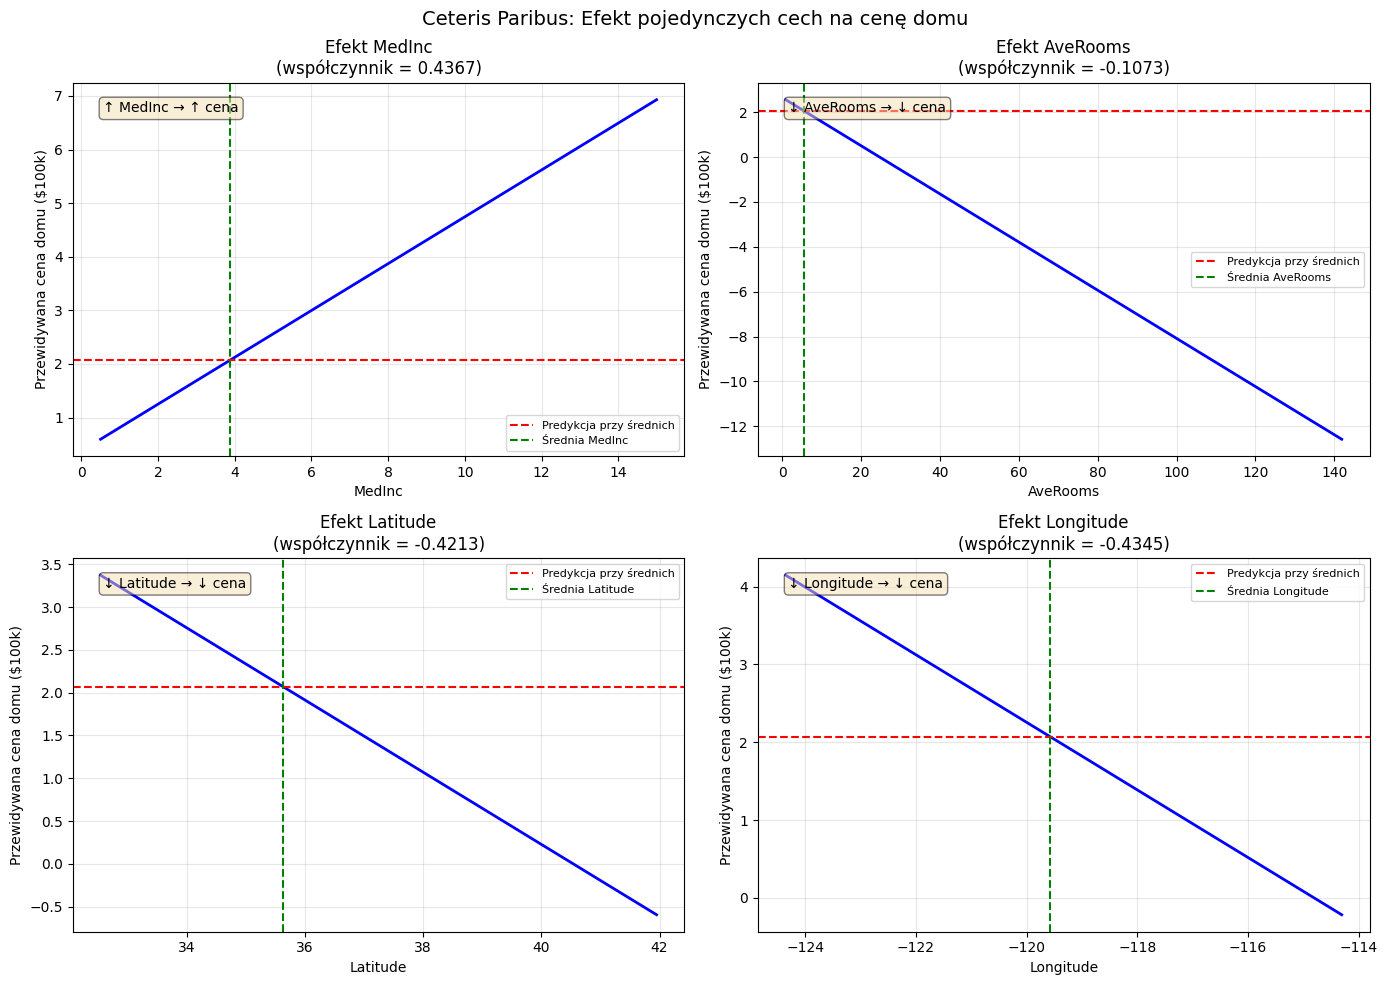


=== Interpretacja ===
MedInc: Wzrost o 1 jednostkę → wzrost ceny o $43669
AveRooms: Wzrost o 1 jednostkę → spadek ceny o $10732
Latitude: Wzrost o 1 jednostkę → spadek ceny o $42131
Longitude: Wzrost o 1 jednostkę → spadek ceny o $43451


In [7]:
# Ceteris Paribus Plots - efekt pojedynczej cechy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
# Dane
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target
# Model
model = LinearRegression()
model.fit(X, y)
print("=== Ceteris Paribus Analysis ===")
print("Jak zmienia się predykcja gdy zmieniamy jedną cechę,")
print("a pozostałe utrzymujemy na średnich wartościach?\n")
# Średnie wartości cech
X_mean = X.mean()
print("Średnie wartości cech:")
print(X_mean)
# Tworzymy dane do analizy dla wybranych cech
features_to_analyze = ['MedInc', 'AveRooms', 'Latitude', 'Longitude']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for idx, feature in enumerate(features_to_analyze):
    # Zakres wartości cechy
    feature_range = np.linspace(X[feature].min(), X[feature].max(), 100)
    # Tworzenie danych: wszystkie cechy na średniej, tylko jedna zmienna
    X_cp = pd.DataFrame([X_mean] * len(feature_range))
    X_cp[feature] = feature_range
    # Predykcja
    y_pred = model.predict(X_cp)
    # Wizualizacja
    ax = axes[idx]
    ax.plot(feature_range, y_pred, 'b-', linewidth=2)
    ax.axhline(y=model.predict([X_mean])[0], color='r', linestyle='--',
               label='Predykcja przy średnich')
    ax.axvline(x=X_mean[feature], color='g', linestyle='--',
               label=f'Średnia {feature}')
    # Nachylenie (współczynnik)
    coef = model.coef_[list(X.columns).index(feature)]
    ax.set_xlabel(f'{feature}')
    ax.set_ylabel('Przewidywana cena domu ($100k)')
    ax.set_title(f'Efekt {feature}\n(współczynnik = {coef:.4f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    # Adnotacja
    direction = "↑" if coef > 0 else "↓"
    ax.text(0.05, 0.95, f'{direction} {feature} → {direction} cena',
            transform=ax.transAxes, fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.suptitle('Ceteris Paribus: Efekt pojedynczych cech na cenę domu', fontsize=14)
plt.tight_layout()
plt.show()
# Podsumowanie interpretacji
print("\n=== Interpretacja ===")
for feature in features_to_analyze:
    coef = model.coef_[list(X.columns).index(feature)]
    if coef > 0:
        print(f"{feature}: Wzrost o 1 jednostkę → wzrost ceny o ${coef*100000:.0f}")
    else:
        print(f"{feature}: Wzrost o 1 jednostkę → spadek ceny o ${abs(coef)*100000:.0f}")


=== Statystyki reszt ===
Średnia reszt (train): 0.000000 (powinna być ~0)
Std reszt (train): 0.7197
Min reszt: -5.9348
Max reszt: 4.1807


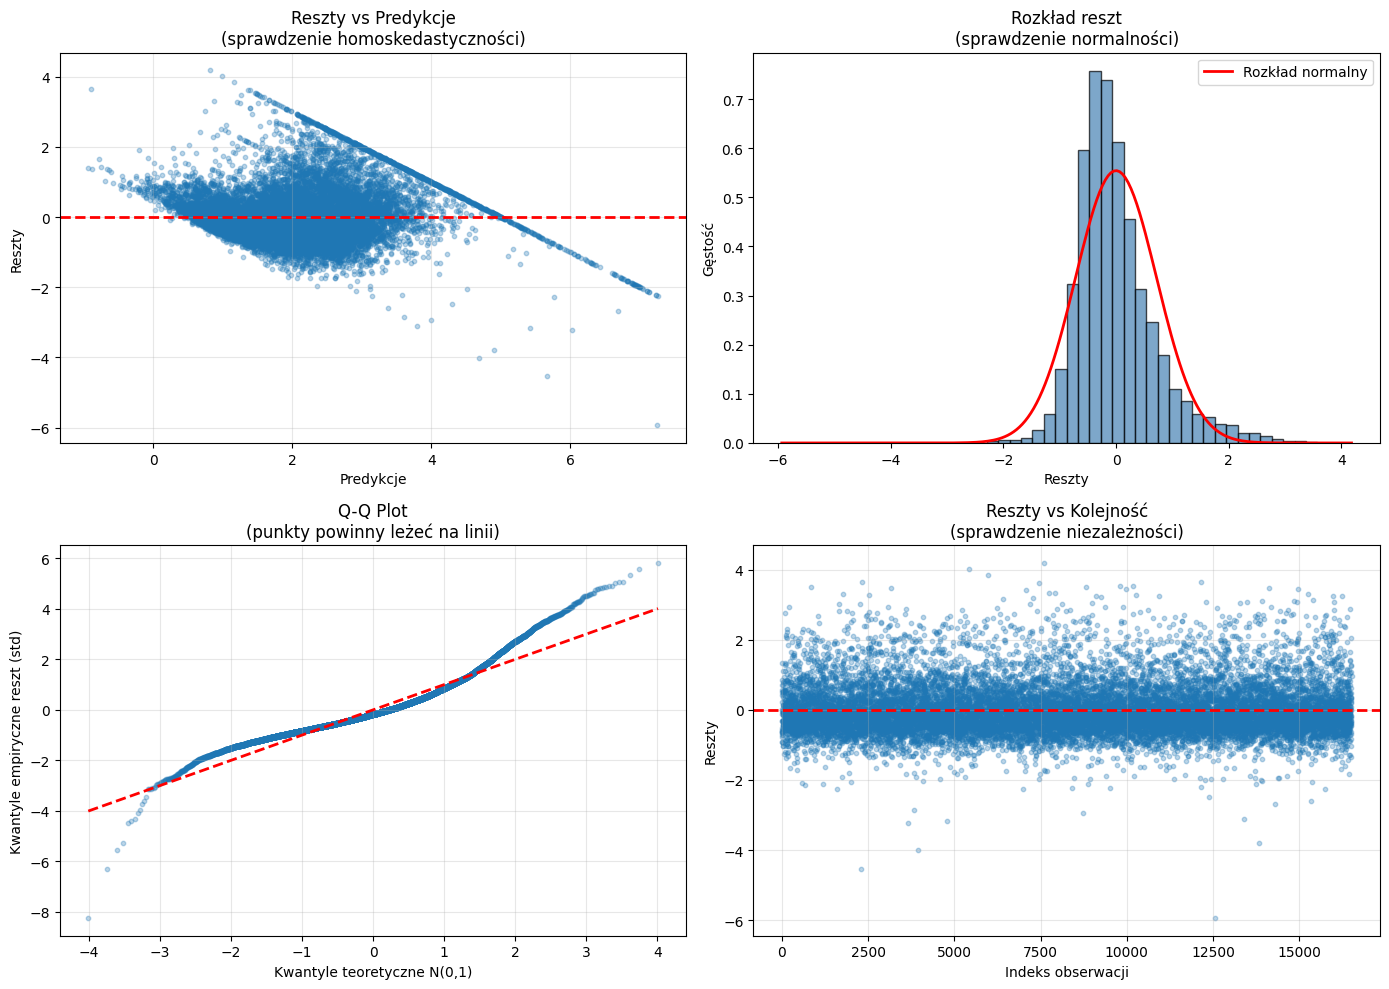


=== Test Jarque-Bera (normalność reszt) ===
Statystyka JB: 9371.4658
p-value (przybliżone): 0.000000
→ Reszty NIE mają rozkładu normalnego (p < 0.05)


In [8]:
# Analiza reszt — z manualnymi narzędziami z Lekcji 16 (bez scipy)
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
# Manualne primitywy z Lekcji 16:
def normal_pdf(x, mu=0.0, sigma=1.0):
    """Gęstość rozkładu N(mu, sigma²)."""
    z = (x - mu) / sigma
    return np.exp(-0.5 * z * z) / (sigma * math.sqrt(2 * math.pi))
def normal_ppf(p):
    """Kwantyl N(0,1) metodą bisekcji (60 iteracji, dokładność ~ 1e-15)."""
    if p <= 0 or p >= 1:
        return float('-inf') if p <= 0 else float('inf')
    lo, hi = -10.0, 10.0
    for _ in range(60):
        mid = (lo + hi) / 2
        cdf_mid = 0.5 * (1 + math.erf(mid / math.sqrt(2)))
        if cdf_mid < p:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2
def jarque_bera(x):
    """Test normalności Jarque-Bera (Lekcja 16): JB = n/6 * (S² + K²/4)."""
    x = np.asarray(x)
    n = len(x)
    m = x.mean()
    d = x - m
    s2 = (d * d).mean()
    s = np.sqrt(s2)
    skew = ((d / s) ** 3).mean()
    kurt = ((d / s) ** 4).mean() - 3
    jb = n / 6 * (skew ** 2 + kurt ** 2 / 4)
    # Przybliżenie p-value przez chi-kwadrat z 2 stopniami swobody: p ≈ exp(-JB/2)
    p_approx = math.exp(-jb / 2)
    return jb, p_approx
# Dane
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Model
model = LinearRegression()
model.fit(X_train, y_train)
# Predykcje i reszty
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test
print("=== Statystyki reszt ===")
print(f"Średnia reszt (train): {residuals_train.mean():.6f} (powinna być ~0)")
print(f"Std reszt (train): {residuals_train.std():.4f}")
print(f"Min reszt: {residuals_train.min():.4f}")
print(f"Max reszt: {residuals_train.max():.4f}")
# Wizualizacja diagnostyczna
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# 1. Reszty vs Predykcje (sprawdzenie homoskedastyczności)
axes[0, 0].scatter(y_pred_train, residuals_train, alpha=0.3, s=10)
axes[0, 0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Predykcje')
axes[0, 0].set_ylabel('Reszty')
axes[0, 0].set_title('Reszty vs Predykcje\n(sprawdzenie homoskedastyczności)')
axes[0, 0].grid(True, alpha=0.3)
# 2. Histogram reszt (sprawdzenie normalności) + manualna krzywa gęstości
axes[0, 1].hist(residuals_train, bins=50, density=True, alpha=0.7, color='steelblue',
edgecolor='black')
x_norm = np.linspace(residuals_train.min(), residuals_train.max(), 200)
axes[0, 1].plot(x_norm, normal_pdf(x_norm, residuals_train.mean(), residuals_train.std()),
                'r-', linewidth=2, label='Rozkład normalny')
axes[0, 1].set_xlabel('Reszty')
axes[0, 1].set_ylabel('Gęstość')
axes[0, 1].set_title('Rozkład reszt\n(sprawdzenie normalności)')
axes[0, 1].legend()
# 3. Manualny Q-Q plot: posortowane reszty vs kwantyle teoretyczne N(0,1)
# Standaryzujemy reszty i porównujemy z kwantylami normalnymi
r_sorted = np.sort(residuals_train)
r_std = (r_sorted - r_sorted.mean()) / r_sorted.std()
n = len(r_std)
# Używamy plotting position (i - 0.5) / n dla każdej obserwacji
theoretical_q = np.array([normal_ppf((i + 0.5) / n) for i in range(n)])
axes[1, 0].scatter(theoretical_q, r_std, alpha=0.3, s=10)
# Linia y = x (punkty idealnie normalne leżą na niej)
q_range = [theoretical_q.min(), theoretical_q.max()]
axes[1, 0].plot(q_range, q_range, 'r--', linewidth=2)
axes[1, 0].set_xlabel('Kwantyle teoretyczne N(0,1)')
axes[1, 0].set_ylabel('Kwantyle empiryczne reszt (std)')
axes[1, 0].set_title('Q-Q Plot\n(punkty powinny leżeć na linii)')
axes[1, 0].grid(True, alpha=0.3)
# 4. Reszty vs kolejność (sprawdzenie niezależności)
axes[1, 1].scatter(range(len(residuals_train)), residuals_train, alpha=0.3, s=10)
axes[1, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Indeks obserwacji')
axes[1, 1].set_ylabel('Reszty')
axes[1, 1].set_title('Reszty vs Kolejność\n(sprawdzenie niezależności)')
axes[1, 1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Test normalności reszt — Jarque-Bera (Lekcja 16) zamiast Shapiro-Wilk (scipy)
jb_stat, p_value = jarque_bera(residuals_train)
print(f"\n=== Test Jarque-Bera (normalność reszt) ===")
print(f"Statystyka JB: {jb_stat:.4f}")
print(f"p-value (przybliżone): {p_value:.6f}")
if p_value < 0.05:
    print("→ Reszty NIE mają rozkładu normalnego (p < 0.05)")
else:
    print("→ Reszty mają rozkład normalny (p >= 0.05)")


In [9]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# Dane
housing = fetch_california_housing()
X, y = housing.data, housing.target
# Podział
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Model
model = LinearRegression()
model.fit(X_train, y_train)
# Predykcje
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
# Obliczenie metryk
def calculate_metrics(y_true, y_pred, n_features=None):
    """Oblicza wszystkie metryki regresji."""
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # Adjusted R² (poprawka na liczbę cech)
    if n_features:
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    else:
        adj_r2 = None
    # MAPE (Mean Absolute Percentage Error)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2,
        'Adjusted R²': adj_r2,
        'MAPE (%)': mape
    }
# Metryki dla train i test
metrics_train = calculate_metrics(y_train, y_pred_train, X_train.shape[1])
metrics_test = calculate_metrics(y_test, y_pred_test, X_test.shape[1])
print("=== Metryki jakości modelu ===\n")
print(f"{'Metryka':<15} {'Train':>12} {'Test':>12}")
print("-" * 40)
for metric in metrics_train.keys():
    train_val = metrics_train[metric]
    test_val = metrics_test[metric]
    if train_val is not None:
        print(f"{metric:<15} {train_val:>12.4f} {test_val:>12.4f}")
# Cross-validation
cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
print(f"\n=== Cross-Validation (5-fold) ===")
print(f"R² per fold: {cv_scores}")
print(f"Średnie R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
# Interpretacja metryk
print("\n=== Interpretacja metryk ===")
print(f"""
• MSE = {metrics_test['MSE']:.4f}
  Średni kwadrat błędu. Wartość w kwadratowych jednostkach targetu.
• RMSE = {metrics_test['RMSE']:.4f}
  Pierwiastek MSE. W jednostkach targetu (tu: $100k).
  → Średni błąd predykcji: ${metrics_test['RMSE']*100000:.0f}
• MAE = {metrics_test['MAE']:.4f}
  Średni błąd absolutny. Mniej wrażliwy na outliers.
  → Typowy błąd: ${metrics_test['MAE']*100000:.0f}
• R² = {metrics_test['R²']:.4f}
  Współczynnik determinacji. Jaki % wariancji y jest wyjaśniony przez model.
  → Model wyjaśnia {metrics_test['R²']*100:.1f}% zmienności cen.
• Adjusted R² = {metrics_test['Adjusted R²']:.4f}
  R² skorygowane o liczbę cech. Karze za dodawanie niepotrzebnych cech.
• MAPE = {metrics_test['MAPE (%)']:.1f}%
  Średni procentowy błąd. Intuicyjny, ale problematyczny gdy y ≈ 0.
""")


=== Metryki jakości modelu ===

Metryka                Train         Test
----------------------------------------
MSE                   0.5179       0.5559
RMSE                  0.7197       0.7456
MAE                   0.5286       0.5332
R²                    0.6126       0.5758
Adjusted R²           0.6124       0.5750
MAPE (%)             31.5020      31.9522

=== Cross-Validation (5-fold) ===
R² per fold: [0.54866323 0.46820691 0.55078434 0.53698703 0.66051406]
Średnie R²: 0.5530 ± 0.0617

=== Interpretacja metryk ===

• MSE = 0.5559
  Średni kwadrat błędu. Wartość w kwadratowych jednostkach targetu.
• RMSE = 0.7456
  Pierwiastek MSE. W jednostkach targetu (tu: $100k).
  → Średni błąd predykcji: $74558
• MAE = 0.5332
  Średni błąd absolutny. Mniej wrażliwy na outliers.
  → Typowy błąd: $53320
• R² = 0.5758
  Współczynnik determinacji. Jaki % wariancji y jest wyjaśniony przez model.
  → Model wyjaśnia 57.6% zmienności cen.
• Adjusted R² = 0.5750
  R² skorygowane o liczbę cech. Kar

=== Variance Inflation Factor (VIF) ===

   Feature      VIF  R² (na inne cechy)
  Latitude 9.297624            0.892446
 Longitude 8.962263            0.888421
  AveRooms 8.342786            0.880136
 AveBedrms 6.994995            0.857041
    MedInc 2.501295            0.600207
  HouseAge 1.241254            0.194363
Population 1.138125            0.121362
  AveOccup 1.008324            0.008256

=== Interpretacja VIF ===
• VIF = 1: Brak korelacji z innymi cechami
• VIF 1-5: Umiarkowana korelacja (akceptowalna)
• VIF 5-10: Wysoka korelacja (należy rozważyć)
• VIF > 10: Poważna multikolinearność (problematyczna!)


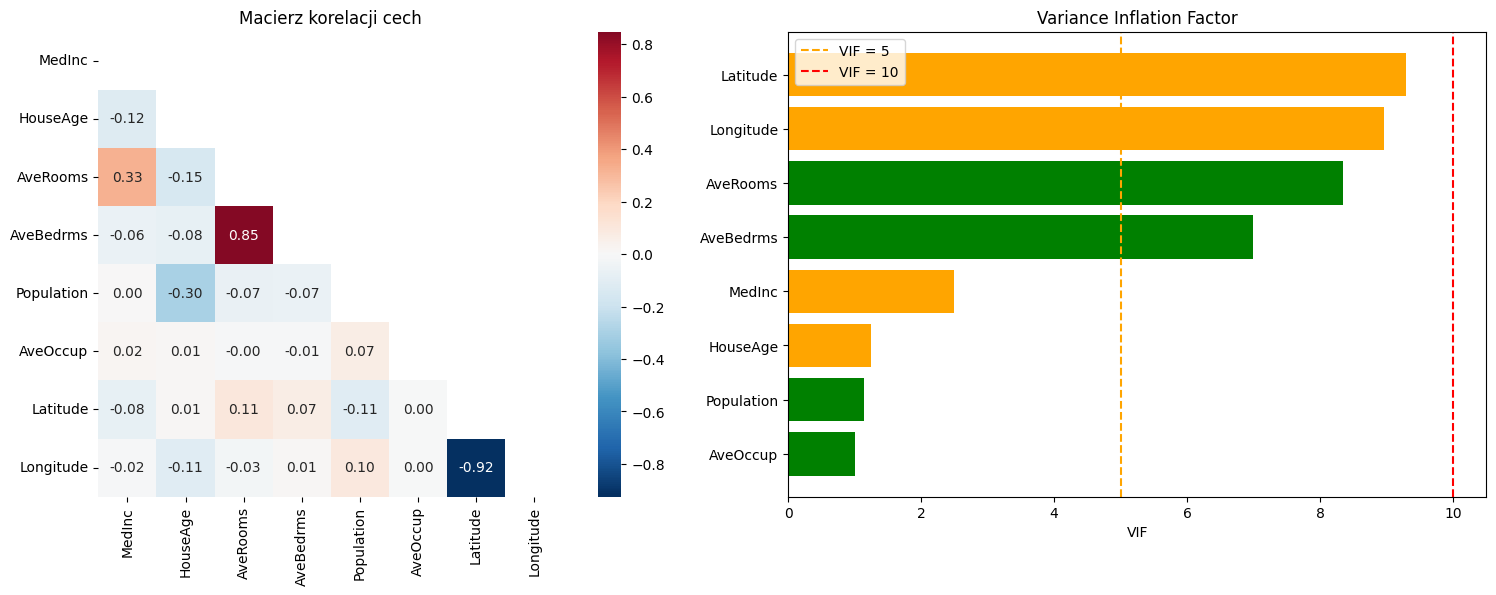


=== Silnie skorelowane pary cech (|r| > 0.7) ===
 Cecha 1   Cecha 2  Korelacja
AveRooms AveBedrms   0.847621
Latitude Longitude  -0.924664


In [10]:
# Variance Inflation Factor (VIF) - wykrywanie multikolinearności
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
# Dane
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
def calculate_vif(X):
    """
    Oblicza VIF dla każdej cechy.
    VIF > 10 wskazuje na problematyczną multikolinearność.
    """
    vif_data = []
    for i, feature in enumerate(X.columns):
        # Regresja jednej cechy na wszystkie pozostałe
        y = X.iloc[:, i]
        X_other = X.drop(columns=[feature])
        model = LinearRegression()
        model.fit(X_other, y)
        r_squared = model.score(X_other, y)
        # VIF = 1 / (1 - R²)
        vif = 1 / (1 - r_squared) if r_squared < 1 else np.inf
        vif_data.append({
            'Feature': feature,
            'VIF': vif,
            'R² (na inne cechy)': r_squared
        })
    return pd.DataFrame(vif_data)
# Obliczenie VIF
vif_df = calculate_vif(X)
print("=== Variance Inflation Factor (VIF) ===\n")
print(vif_df.sort_values('VIF', ascending=False).to_string(index=False))
print("\n=== Interpretacja VIF ===")
print("• VIF = 1: Brak korelacji z innymi cechami")
print("• VIF 1-5: Umiarkowana korelacja (akceptowalna)")
print("• VIF 5-10: Wysoka korelacja (należy rozważyć)")
print("• VIF > 10: Poważna multikolinearność (problematyczna!)")
# Macierz korelacji
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# Heatmap korelacji
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=axes[0], square=True)
axes[0].set_title('Macierz korelacji cech')
# VIF bar plot
colors = ['green' if v < 5 else 'orange' if v < 10 else 'red' for v in vif_df['VIF']]
vif_sorted = vif_df.sort_values('VIF', ascending=True)
axes[1].barh(vif_sorted['Feature'], vif_sorted['VIF'], color=colors)
axes[1].axvline(x=5, color='orange', linestyle='--', label='VIF = 5')
axes[1].axvline(x=10, color='red', linestyle='--', label='VIF = 10')
axes[1].set_xlabel('VIF')
axes[1].set_title('Variance Inflation Factor')
axes[1].legend()
plt.tight_layout()
plt.show()
# Wykrywanie problematycznych par cech
print("\n=== Silnie skorelowane pary cech (|r| > 0.7) ===")
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.7:
            high_corr_pairs.append({
                'Cecha 1': corr_matrix.columns[i],
                'Cecha 2': corr_matrix.columns[j],
                'Korelacja': corr_matrix.iloc[i, j]
            })
if high_corr_pairs:
    print(pd.DataFrame(high_corr_pairs).to_string(index=False))


In [ ]:
# Porównanie dwóch sposobów estymacji tych samych parametrów:
# - LinearRegression: rozwiązanie analityczne (OLS, closed-form)
# - SGDRegressor: iteracyjny gradient descent (Lekcja 19)
import numpy as np
import pandas as pd
import time
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
# Dane
housing = fetch_california_housing()
X, y = housing.data, housing.target
# Podział
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Modele do porównania — oba estymują ten sam model liniowy, różną metodą
models = {
    'LinearRegression (OLS)': LinearRegression(),
    'SGDRegressor (GD)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SGDRegressor(max_iter=1000, tol=1e-4, random_state=42))
    ]),
}
results = []
print("=== OLS vs Gradient Descent: ten sam model, różna metoda ===\n")
for name, model in models.items():
    # Trening z pomiarem czasu — time.perf_counter() (polityka z Lekcji 8)
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time
    # Predykcje
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    # Metryki
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    test_mse = mean_squared_error(y_test, y_pred_test)
    # Cross-validation
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
    results.append({
        'Model': name,
        'Train R²': train_r2,
        'Test R²': test_r2,
        'Test MSE': test_mse,
        'CV R² (mean)': cv_scores.mean(),
        'CV R² (std)': cv_scores.std(),
        'Train Time (s)': train_time
    })
    print(f"{name}:")
    print(f"  Train R²: {train_r2:.4f}")
    print(f"  Test R²: {test_r2:.4f}")
    print(f"  CV R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  Train time: {train_time:.4f}s")
    print()
# Tabela porównawcza
results_df = pd.DataFrame(results)
print("\n=== Podsumowanie ===")
print(results_df.to_string(index=False))
# Wniosek: dla małych/średnich danych OLS daje dokładniejsze i szybsze rozwiązanie.
# Dla bardzo dużych danych (miliony próbek) SGD wygrywa — nie musi odwracać macierzy X'X.
print("\n→ OLS: rozwiązanie analityczne (zawsze globalne minimum MSE).")
print("→ SGD: iteracyjne, ale skaluje się lepiej dla big data i online learning.")


=== Porównanie z Baseline ===

Model                            MSE       RMSE         R²
------------------------------------------------------------
Baseline (średnia)            1.3107     1.1449    -0.0002
Baseline (mediana)            1.3762     1.1731    -0.0502
LinearRegression              0.5559     0.7456     0.5758

→ LinearRegression redukuje MSE o 57.6% względem baseline!


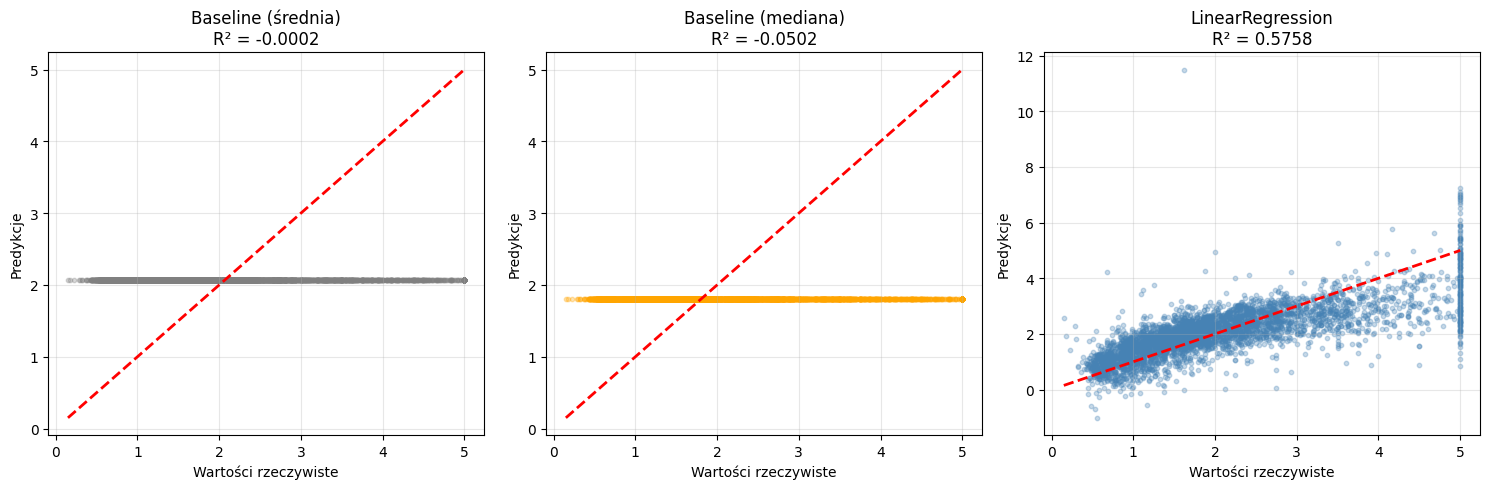

In [12]:
# Porównanie z baseline (przewidywanie średniej)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
# Dane
housing = fetch_california_housing()
X, y = housing.data, housing.target
# Podział
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Modele
baseline_mean = DummyRegressor(strategy='mean')  # Przewiduje średnią
baseline_median = DummyRegressor(strategy='median')  # Przewiduje medianę
linear_model = LinearRegression()
# Trening
baseline_mean.fit(X_train, y_train)
baseline_median.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
# Predykcje
y_pred_mean = baseline_mean.predict(X_test)
y_pred_median = baseline_median.predict(X_test)
y_pred_linear = linear_model.predict(X_test)
# Metryki
print("=== Porównanie z Baseline ===\n")
print(f"{'Model':<25} {'MSE':>10} {'RMSE':>10} {'R²':>10}")
print("-" * 60)
for name, y_pred in [('Baseline (średnia)', y_pred_mean),
                      ('Baseline (mediana)', y_pred_median),
                      ('LinearRegression', y_pred_linear)]:
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    print(f"{name:<25} {mse:>10.4f} {rmse:>10.4f} {r2:>10.4f}")
# Poprawa względem baseline
baseline_mse = mean_squared_error(y_test, y_pred_mean)
linear_mse = mean_squared_error(y_test, y_pred_linear)
improvement = (baseline_mse - linear_mse) / baseline_mse * 100
print(f"\n→ LinearRegression redukuje MSE o {improvement:.1f}% względem baseline!")
# Wizualizacja
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
models_data = [
    ('Baseline (średnia)', y_pred_mean, 'gray'),
    ('Baseline (mediana)', y_pred_median, 'orange'),
    ('LinearRegression', y_pred_linear, 'steelblue')
]
for ax, (name, y_pred, color) in zip(axes, models_data):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10, color=color)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
    r2 = r2_score(y_test, y_pred)
    ax.set_xlabel('Wartości rzeczywiste')
    ax.set_ylabel('Predykcje')
    ax.set_title(f'{name}\nR² = {r2:.4f}')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


=== Dane ===
Liczba obserwacji: 50
X: zakres [0.0, 10.0]
y: zakres [2.3, 32.9]

=== Wyuczone parametry ===
Wyraz wolny (intercept): w₀ = 2.1289 (prawdziwy: 5)
Nachylenie (slope): w₁ = 2.8840 (prawdziwy: 2)

=== Parametry modelu sklearn ===
Wyraz wolny (intercept_): 2.4644
Współczynnik (coef_): 2.8346

=== Metryki ===
Train MSE: 3.3571
Test MSE: 3.2196
Train R²: 0.9567
Test R²: 0.9459


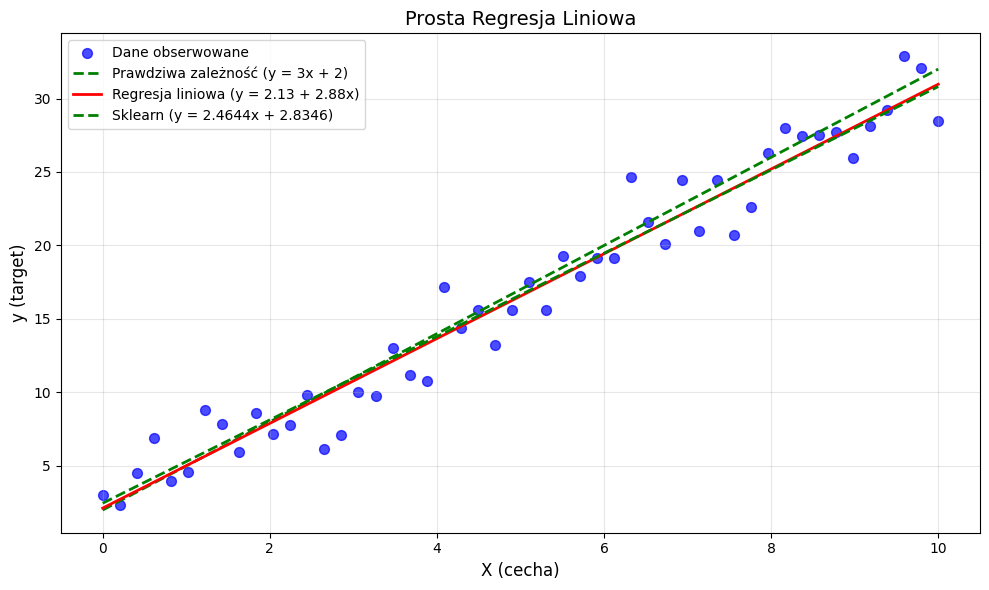

In [37]:
# zadanie 1

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)
X = np.linspace(0,10,50)
y_true = 3*X + 2
noise = np.random.normal (0,2,size=X.shape)
y = y_true +noise

print("=== Dane ===")
print(f"Liczba obserwacji: {len(X)}")
print(f"X: zakres [{X.min():.1f}, {X.max():.1f}]")
print(f"y: zakres [{y.min():.1f}, {y.max():.1f}]")

x_mean = X.mean()
y_mean = y.mean()


numerator = np.sum((X-x_mean)*(y-y_mean))
denominator = np.sum((X-x_mean)**2)
w1=numerator/denominator

w0= y_mean - w1*x_mean
print(f"\n=== Wyuczone parametry ===")
print(f"Wyraz wolny (intercept): w₀ = {w0:.4f} (prawdziwy: 5)")
print(f"Nachylenie (slope): w₁ = {w1:.4f} (prawdziwy: 2)")
y_pred = w0+w1*X


#skleaern

X = X.reshape(-1, 1)
y = y.ravel()

X_train,X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)

print(f"\n=== Parametry modelu sklearn ===")
print(f"Wyraz wolny (intercept_): {model.intercept_:.4f}")
print(f"Współczynnik (coef_): {model.coef_[0]:.4f}")

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
y_pred_sklearn = model.predict(X)

print(f"\n=== Metryki ===")
print(f"Train MSE: {mean_squared_error(y_train, y_pred_train):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_pred_test):.4f}")
print(f"Train R²: {r2_score(y_train, y_pred_train):.4f}")
print(f"Test R²: {r2_score(y_test, y_pred_test):.4f}")


plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.7, label='Dane obserwowane', color='blue', s=50)
plt.plot(X, y_true, 'g--', label='Prawdziwa zależność (y = 3x + 2)', linewidth=2)
plt.plot(X, y_pred, 'r-', label=f'Regresja liniowa (y = {w0:.2f} + {w1:.2f}x)',
linewidth=2)
plt.plot(X , y_pred_sklearn, 'g--', label=f'Sklearn (y = {model.intercept_:.4f}x + {model.coef_[0]:.4f})', linewidth=2)
plt.xlabel('X (cecha)', fontsize=12)
plt.ylabel('y (target)', fontsize=12)
plt.title('Prosta Regresja Liniowa', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Zadanie 2 – Interpretacja współczynników regresji

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

n = 200

cena = np.random.uniform(50, 200, n)
reklama = np.random.uniform(100, 5000, n)
sezon = np.random.randint(1, 5, n)

noise = np.random.normal(0, 500, n)

sprzedaz = -2*cena + 0.5*reklama + 100*sezon + 5000 + noise

X = pd.DataFrame({
    'cena': cena,
    'reklama': reklama,
    'sezon': sezon
})

y = sprzedaz

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("=== PARAMETRY MODELU ===")
print(f"Wyraz wolny: {model.intercept_:.2f}")

for nazwa, wspolczynnik in zip(X.columns, model.coef_):
    print(f"{nazwa}: {wspolczynnik:.4f}")

y_pred = model.predict(X_test)

print("\n=== METRYKI MODELU ===")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R²: {r2_score(y_test, y_pred):.4f}")

print("\n=== ANALIZA BIZNESOWA ===")
for nazwa, wspolczynnik in zip(X.columns, model.coef_):
  print(
      f"Zwiększenie {nazwa} o 1000 "
      f"zwiększa przewidywaną sprzedaż o {wspolczynnik*1000:.2f} jednostek."
  )


=== PARAMETRY MODELU ===
Wyraz wolny: 4867.49
cena: -0.2708
reklama: 0.5109
sezon: 53.9142

=== METRYKI MODELU ===
MSE: 208209.35
R²: 0.6147

=== ANALIZA BIZNESOWA ===
Zwiększenie cena o 1000 zwiększa przewidywaną sprzedaż o -270.82 jednostek.
Zwiększenie reklama o 1000 zwiększa przewidywaną sprzedaż o 510.94 jednostek.
Zwiększenie sezon o 1000 zwiększa przewidywaną sprzedaż o 53914.15 jednostek.


In [40]:
#Zadanie 3 – R² i MSE


# Zadanie – Regresja liniowa na California Housing

import numpy as np
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

housing = fetch_california_housing()

X = housing.data
y = housing.target

print("=== INFORMACJE O DANYCH ===")
print("Liczba obserwacji:", X.shape[0])
print("Liczba cech:", X.shape[1])
print("Nazwy cech:", housing.feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return mse, rmse, mae, r2

train_metrics = calculate_metrics(y_train, y_pred_train)
test_metrics = calculate_metrics(y_test, y_pred_test)

results = pd.DataFrame(
    [train_metrics, test_metrics],
    columns=["MSE", "RMSE", "MAE", "R²"],
    index=["Train", "Test"]
)

print("\n=== PORÓWNANIE METRYK ===")
print(results.round(4))

r2_test = r2_score(y_test, y_pred_test)

print("\n=== INTERPRETACJA R² ===")
print(f"R² na zbiorze testowym: {r2_test:.4f}")
print(f"Model wyjaśnia {r2_test * 100:.2f}% wariancji zmiennej zależnej.")
print(f"Pozostałe {100 - r2_test * 100:.2f}% wariancji nie jest wyjaśnione przez model.")
#Wyjaśnialność na poziomie 57% jest dosyć słabym wynikiem ale lepsze to niż nic

=== INFORMACJE O DANYCH ===
Liczba obserwacji: 20640
Liczba cech: 8
Nazwy cech: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)

=== PORÓWNANIE METRYK ===
          MSE    RMSE     MAE      R²
Train  0.5179  0.7197  0.5286  0.6126
Test   0.5559  0.7456  0.5332  0.5758

=== INTERPRETACJA R² ===
R² na zbiorze testowym: 0.5758
Model wyjaśnia 57.58% wariancji zmiennej zależnej.
Pozostałe 42.42% wariancji nie jest wyjaśnione przez model.


=== ANALIZA RESZT ===
Średnia reszt: 0.0035
Odchylenie standardowe: 0.7456
Minimum: -9.8753
Maksimum: 4.1484


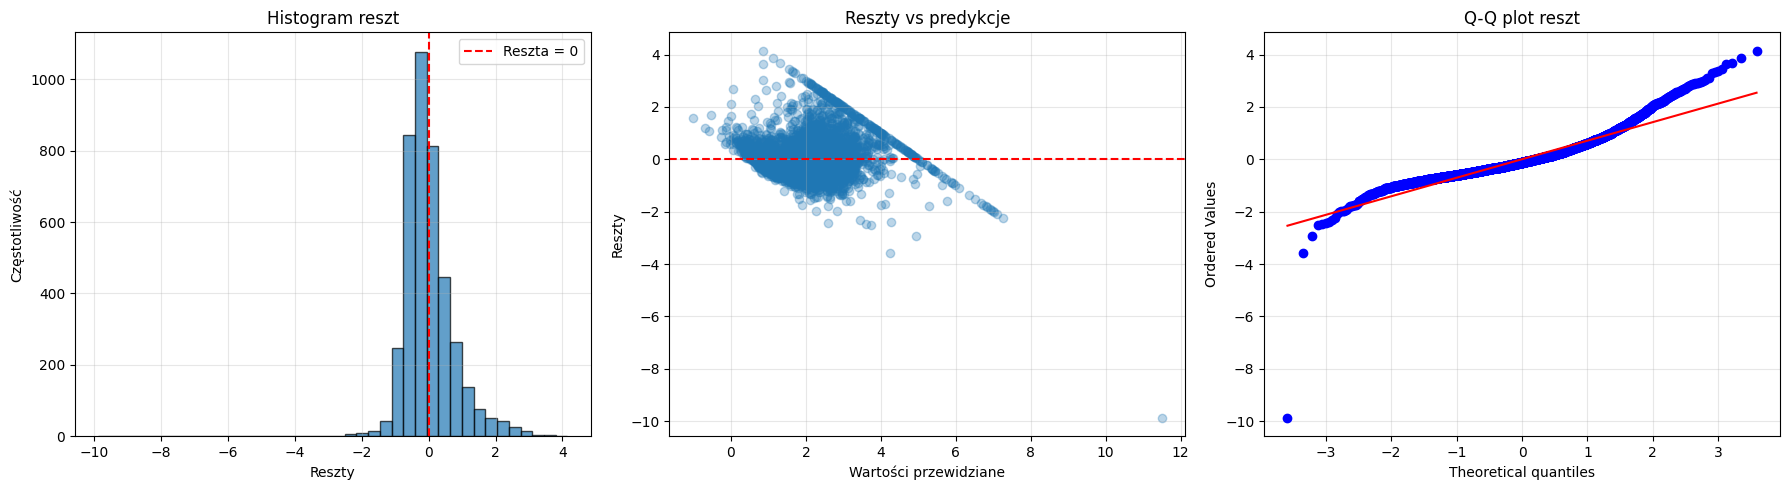


=== TEST NORMALNOŚCI ===
Statystyka testowa: 912.4121
P-value: 0.000000
Odrzucamy H0 – reszty odbiegają od rozkładu normalnego.


In [41]:

# Zadanie 5 – Analiza reszt regresji liniowej
# Dataset: California Housing

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy import stats

housing = fetch_california_housing()

X = housing.data
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

residuals = y_test - y_pred

print("=== ANALIZA RESZT ===")
print(f"Średnia reszt: {np.mean(residuals):.4f}")
print(f"Odchylenie standardowe: {np.std(residuals):.4f}")
print(f"Minimum: {np.min(residuals):.4f}")
print(f"Maksimum: {np.max(residuals):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(
    residuals,
    bins=40,
    edgecolor='black',
    alpha=0.7
)

axes[0].axvline(
    0,
    color='red',
    linestyle='--',
    label='Reszta = 0'
)

axes[0].set_title('Histogram reszt')
axes[0].set_xlabel('Reszty')
axes[0].set_ylabel('Częstotliwość')
axes[0].legend()
axes[0].grid(alpha=0.3)

#Wykres 2 – Reszty vs predykcje
axes[1].scatter(
    y_pred,
    residuals,
    alpha=0.3
)

axes[1].axhline(
    0,
    color='red',
    linestyle='--'
)

axes[1].set_title('Reszty vs predykcje')
axes[1].set_xlabel('Wartości przewidziane')
axes[1].set_ylabel('Reszty')
axes[1].grid(alpha=0.3)

#Wykres 3 – Q-Q plot
stats.probplot(
    residuals,
    dist='norm',
    plot=axes[2]
)

axes[2].set_title('Q-Q plot reszt')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

statistic, p_value = stats.normaltest(residuals)

print("\n=== TEST NORMALNOŚCI ===")
print(f"Statystyka testowa: {statistic:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Odrzucamy H0 – reszty odbiegają od rozkładu normalnego.")
else:
    print("Brak podstaw do odrzucenia H0 – nie wykryto istotnego odstępstwa od normalności.")


=== INFORMACJE O DANYCH ===
Liczba obserwacji: 20640
Liczba cech: 8

=== PORÓWNANIE CROSS-VALIDATION ===
 Liczba foldów  Średnie R²  Odchylenie standardowe
             5    0.601378                0.017010
            10    0.600075                0.022185

=== WYNIKI DLA K=5 ===
Fold 1: R² = 0.5758
Fold 2: R² = 0.6137
Fold 3: R² = 0.6086
Fold 4: R² = 0.6213
Fold 5: R² = 0.5875

=== WYNIKI DLA K=10 ===
Fold 1: R² = 0.5808
Fold 2: R² = 0.5702
Fold 3: R² = 0.6344
Fold 4: R² = 0.5945
Fold 5: R² = 0.6156
Fold 6: R² = 0.6027
Fold 7: R² = 0.5907
Fold 8: R² = 0.6399
Fold 9: R² = 0.5778
Fold 10: R² = 0.5941


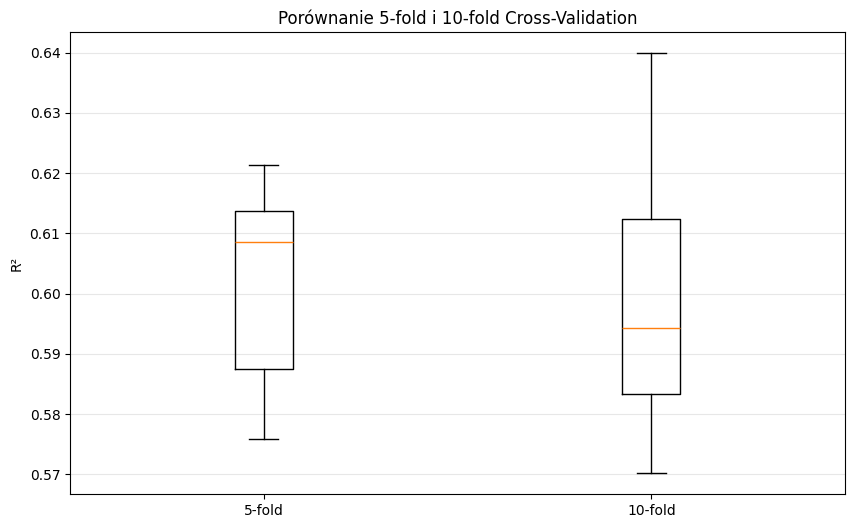


=== ANALIZA STABILNOŚCI ===
5-fold CV ma mniejsze odchylenie standardowe.
Wyniki 5-fold są bardziej stabilne.

Średnie R² dla K=5: 0.6014
Średnie R² dla K=10: 0.6001


In [43]:
# Zadanie 6

# Zadanie – 5-fold vs 10-fold Cross-Validation
# Dataset: California Housing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X = housing.data
y = housing.target

print("=== INFORMACJE O DANYCH ===")
print("Liczba obserwacji:", X.shape[0])
print("Liczba cech:", X.shape[1])

model = Pipeline([
    ('scaler', StandardScaler()),
    ('regression', LinearRegression())
])

cv_5 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_5 = cross_val_score(
    model,
    X,
    y,
    cv=cv_5,
    scoring='r2'
)

cv_10 = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scores_10 = cross_val_score(
    model,
    X,
    y,
    cv=cv_10,
    scoring='r2'
)

mean_5 = scores_5.mean()
std_5 = scores_5.std()

mean_10 = scores_10.mean()
std_10 = scores_10.std()

results = pd.DataFrame({
    'Liczba foldów': [5, 10],
    'Średnie R²': [mean_5, mean_10],
    'Odchylenie standardowe': [std_5, std_10]
})

print("\n=== PORÓWNANIE CROSS-VALIDATION ===")
print(results.to_string(index=False))

print("\n=== WYNIKI DLA K=5 ===")
for i, score in enumerate(scores_5, 1):
    print(f"Fold {i}: R² = {score:.4f}")

print("\n=== WYNIKI DLA K=10 ===")
for i, score in enumerate(scores_10, 1):
    print(f"Fold {i}: R² = {score:.4f}")

plt.figure(figsize=(10, 6))

plt.boxplot(
    [scores_5, scores_10],
    tick_labels=['5-fold', '10-fold']
)

plt.ylabel('R²')
plt.title('Porównanie 5-fold i 10-fold Cross-Validation')
plt.grid(axis='y', alpha=0.3)

plt.show()

print("\n=== ANALIZA STABILNOŚCI ===")

if std_5 < std_10:
    print("5-fold CV ma mniejsze odchylenie standardowe.")
    print("Wyniki 5-fold są bardziej stabilne.")
elif std_10 < std_5:
    print("10-fold CV ma mniejsze odchylenie standardowe.")
    print("Wyniki 10-fold są bardziej stabilne.")
else:
    print("Obie metody mają takie samo odchylenie standardowe.")

print(f"\nŚrednie R² dla K=5: {mean_5:.4f}")
print(f"Średnie R² dla K=10: {mean_10:.4f}")


=== DANE ===
Liczba obserwacji: 20640
Liczba cech: 8
Nazwy cech: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

=== RANKING WAŻNOŚCI CECH ===
     Cecha  Współczynnik  Wartość bezwzględna
  Latitude       -0.8969               0.8969
 Longitude       -0.8698               0.8698
    MedInc        0.8544               0.8544
 AveBedrms        0.3393               0.3393
  AveRooms       -0.2944               0.2944
  HouseAge        0.1225               0.1225
  AveOccup       -0.0408               0.0408
Population       -0.0023               0.0023

=== TOP 3 NAJWAŻNIEJSZE CECHY ===
1. Latitude: współczynnik = -0.8969
2. Longitude: współczynnik = -0.8698
3. MedInc: współczynnik = 0.8544


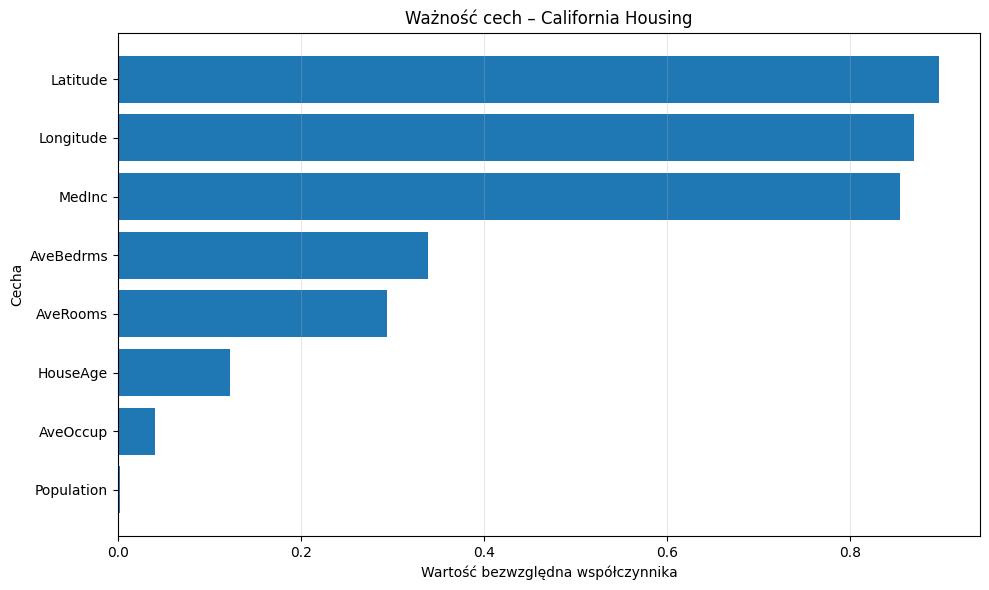

In [46]:
#zadanie 7

# Dataset: California Housing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = housing.target

print("=== DANE ===")
print("Liczba obserwacji:", X.shape[0])
print("Liczba cech:", X.shape[1])
print("Nazwy cech:", X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

coefficients = model.coef_

feature_importance = pd.DataFrame({
    'Cecha': X.columns,
    'Współczynnik': coefficients,
    'Wartość bezwzględna': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by='Wartość bezwzględna',
    ascending=False
).reset_index(drop=True)

print("\n=== RANKING WAŻNOŚCI CECH ===")
print(feature_importance.round(4).to_string(index=False))

top_3 = feature_importance.head(3)

print("\n=== TOP 3 NAJWAŻNIEJSZE CECHY ===")

for i, row in top_3.iterrows():
    print(
        f"{i+1}. {row['Cecha']}: "
        f"współczynnik = {row['Współczynnik']:.4f}"
    )

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Cecha'],
    feature_importance['Wartość bezwzględna']
)

plt.xlabel('Wartość bezwzględna współczynnika')
plt.ylabel('Cecha')
plt.title('Ważność cech – California Housing')

plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


In [50]:

# Zadanie 8 – Predykcja dla nowych danych

import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_test_pred = model.predict(X_test)

print("Ocena modelu:")
print(f"R²: {r2_score(y_test, y_test_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_test_pred):.4f}")

new_data = pd.DataFrame({
    'MedInc': [3.0, 5.0, 8.0, 2.0, 6.5],
    'HouseAge': [20, 30, 15, 40, 25],
    'AveRooms': [5.0, 6.0, 7.0, 4.5, 6.5],
    'AveBedrms': [1.0, 1.1, 1.0, 1.2, 1.0],
    'Population': [1000, 1500, 800, 2000, 1200],
    'AveOccup': [3.0, 2.8, 2.5, 4.0, 2.7],
    'Latitude': [34.0, 37.5, 34.1, 36.0, 37.8],
    'Longitude': [-118.2, -122.0, -118.4, -119.5, -122.3]
})

predictions = model.predict(new_data)

results = new_data.copy()
results['Predykcja ceny (100 tys. USD)'] = predictions
results['Predykcja ceny (USD)'] = predictions * 100000

print("\nPredykcje dla nowych obserwacji:")
display(results.round(2))

print("\nInterpretacja:")
for i, prediction in enumerate(predictions, start=1):
    print(
        f"Obserwacja {i}: "
        f"przewidywana wartość wynosi około "
        f"${prediction * 100000:,.0f}"
    )


Ocena modelu:
R²: 0.5758
MSE: 0.5559

Predykcje dla nowych obserwacji:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Predykcja ceny (100 tys. USD),Predykcja ceny (USD)
0,3.0,20,5.0,1.0,1000,3.0,34.0,-118.2,1.66,166250.05
1,5.0,30,6.0,1.1,1500,2.8,37.5,-122.0,2.79,279059.15
2,8.0,15,7.0,1.0,800,2.5,34.1,-118.4,3.66,365753.85
3,2.0,40,4.5,1.2,2000,4.0,36.0,-119.5,1.35,134528.10
4,6.5,25,6.5,1.0,1200,2.7,37.8,-122.3,3.28,328014.26



Interpretacja:
Obserwacja 1: przewidywana wartość wynosi około $166,250
Obserwacja 2: przewidywana wartość wynosi około $279,059
Obserwacja 3: przewidywana wartość wynosi około $365,754
Obserwacja 4: przewidywana wartość wynosi około $134,528
Obserwacja 5: przewidywana wartość wynosi około $328,014


VIF przed usunięciem cechy:


,Cecha,VIF
0,Latitude,9.21
1,Longitude,8.88
2,AveRooms,7.92
3,AveBedrms,6.61
4,MedInc,2.54
5,HouseAge,1.24
6,Population,1.13
7,AveOccup,1.01



Cechy z VIF > 5:


,Cecha,VIF
0,Latitude,9.21
1,Longitude,8.88
2,AveRooms,7.92
3,AveBedrms,6.61



Usuwana cecha: Latitude

VIF po usunięciu cechy:


,Cecha,VIF
0,AveRooms,7.19
1,AveBedrms,6.34
2,MedInc,2.13
3,HouseAge,1.15
4,Population,1.12
5,Longitude,1.03
6,AveOccup,1.01



Cechy z VIF > 5 po usunięciu:


,Cecha,VIF
0,AveRooms,7.19
1,AveBedrms,6.34



Porównanie modeli:


,Model,R² test,Średnie R² CV,Odchylenie standardowe CV
0,Wszystkie cechy,0.5758,0.6115,0.0124
1,Bez cechy Latitude,0.5103,0.5451,0.0166


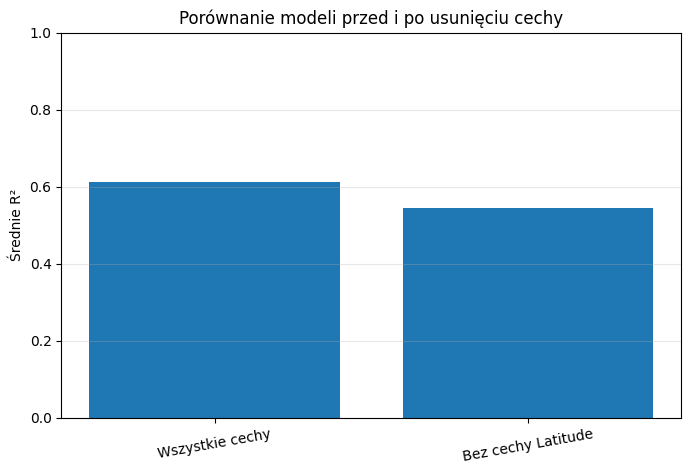


Interpretacja:
Usunięta cecha: Latitude
Zmiana średniego R²: -0.0664
Średnie R² spadło – model po usunięciu cechy uzyskał gorszy wynik.


In [51]:
# Zadanie 10 – Multikolinearność i VIF

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

def calculate_vif(data):
    data_with_constant = add_constant(data)

    vif_data = pd.DataFrame()
    vif_data["Cecha"] = data.columns

    vif_data["VIF"] = [
        variance_inflation_factor(
            data_with_constant.values, i + 1
        )
        for i in range(len(data.columns))
    ]

    return vif_data.sort_values(
        by="VIF",
        ascending=False
    ).reset_index(drop=True)


vif_before = calculate_vif(X_train)

print("VIF przed usunięciem cechy:")
display(vif_before.round(2))

print("\nCechy z VIF > 5:")
display(vif_before[vif_before["VIF"] > 5].round(2))


most_problematic_feature = vif_before.iloc[0]["Cecha"]

print(
    "\nUsuwana cecha:",
    most_problematic_feature
)

X_train_reduced = X_train.drop(
    columns=[most_problematic_feature]
)

X_test_reduced = X_test.drop(
    columns=[most_problematic_feature]
)

vif_after = calculate_vif(X_train_reduced)

print("\nVIF po usunięciu cechy:")
display(vif_after.round(2))

print("\nCechy z VIF > 5 po usunięciu:")
display(vif_after[vif_after["VIF"] > 5].round(2))


model_before = LinearRegression()
model_before.fit(X_train, y_train)

y_pred_before = model_before.predict(X_test)

r2_test_before = r2_score(
    y_test,
    y_pred_before
)


model_after = LinearRegression()
model_after.fit(X_train_reduced, y_train)

y_pred_after = model_after.predict(X_test_reduced)

r2_test_after = r2_score(
    y_test,
    y_pred_after
)


cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_before = cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

scores_after = cross_val_score(
    LinearRegression(),
    X_train_reduced,
    y_train,
    cv=cv,
    scoring="r2"
)


comparison = pd.DataFrame({
    "Model": [
        "Wszystkie cechy",
        f"Bez cechy {most_problematic_feature}"
    ],
    "R² test": [
        r2_test_before,
        r2_test_after
    ],
    "Średnie R² CV": [
        scores_before.mean(),
        scores_after.mean()
    ],
    "Odchylenie standardowe CV": [
        scores_before.std(),
        scores_after.std()
    ]
})

print("\nPorównanie modeli:")
display(comparison.round(4))


plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Średnie R² CV"]
)

plt.ylabel("Średnie R²")
plt.title("Porównanie modeli przed i po usunięciu cechy")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)

plt.show()


difference = scores_after.mean() - scores_before.mean()

print("\nInterpretacja:")
print(f"Usunięta cecha: {most_problematic_feature}")
print(f"Zmiana średniego R²: {difference:.4f}")

if difference > 0:
    print("Średnie R² wzrosło – model po usunięciu cechy uzyskał lepszy wynik.")
elif difference < 0:
    print("Średnie R² spadło – model po usunięciu cechy uzyskał gorszy wynik.")
else:
    print("Średnie R² pozostało praktycznie bez zmian.")


MODEL BAZOWY
R²: 0.5758

MODEL PO FEATURE ENGINEERING
R²: 0.6140

Zmiana R²: 6.64%

Porównanie modeli:


,Model,R²
0,Model bazowy,0.5758
1,Model po Feature Engineering,0.6140



WALIDACJA KRZYŻOWA
Model bazowy: 0.6115 +/- 0.0124
Model po Feature Engineering: 0.6235 +/- 0.0510


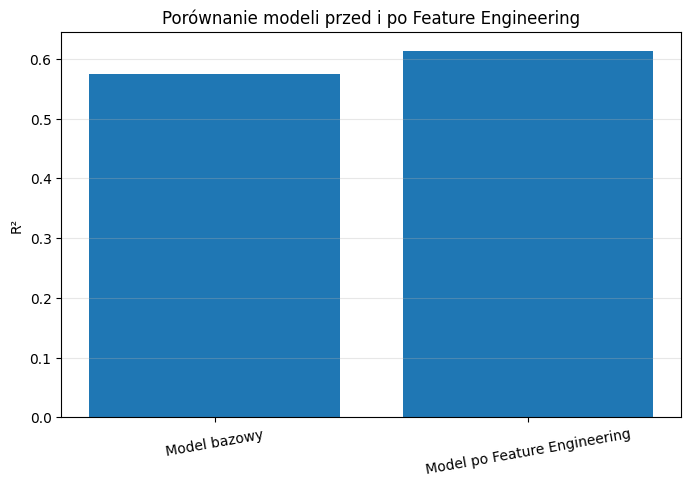


OCENA WYNIKU
Osiągnięto poprawę R² o co najmniej 5%.


In [55]:
# Zadanie 13 – Feature Engineering dla regresji

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

def create_features(data):
    df = data.copy()

    df["MedInc_AveRooms"] = (
        df["MedInc"] * df["AveRooms"]
    )

    df["MedInc_HouseAge"] = (
        df["MedInc"] * df["HouseAge"]
    )

    df["Log_MedInc"] = np.log1p(df["MedInc"])
    df["Log_Population"] = np.log1p(df["Population"])

    df["Sqrt_AveRooms"] = np.sqrt(
        df["AveRooms"].clip(lower=0)
    )

    df["Sqrt_AveOccup"] = np.sqrt(
        df["AveOccup"].clip(lower=0)
    )

    df["MedInc_Bin"] = pd.cut(
        df["MedInc"],
        bins=[-np.inf, 2.5, 4.5, np.inf],
        labels=False
    )

    df["HouseAge_Bin"] = pd.cut(
        df["HouseAge"],
        bins=[-np.inf, 20, 40, np.inf],
        labels=False
    )

    return df


X_train_fe = create_features(X_train)
X_test_fe = create_features(X_test)

baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

fe_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

fe_model.fit(X_train_fe, y_train)

fe_pred = fe_model.predict(X_test_fe)

fe_r2 = r2_score(
    y_test,
    fe_pred
)

improvement = (
    (fe_r2 - baseline_r2) / abs(baseline_r2)
) * 100

print("MODEL BAZOWY")
print(f"R²: {baseline_r2:.4f}")

print("\nMODEL PO FEATURE ENGINEERING")
print(f"R²: {fe_r2:.4f}")

print(f"\nZmiana R²: {improvement:.2f}%")


comparison = pd.DataFrame({
    "Model": [
        "Model bazowy",
        "Model po Feature Engineering"
    ],
    "R²": [
        baseline_r2,
        fe_r2
    ]
})

print("\nPorównanie modeli:")
display(comparison.round(4))


cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

fe_cv = cross_val_score(
    fe_model,
    X_train_fe,
    y_train,
    cv=cv,
    scoring="r2"
)

print("\nWALIDACJA KRZYŻOWA")

print(
    f"Model bazowy: "
    f"{baseline_cv.mean():.4f} "
    f"+/- {baseline_cv.std():.4f}"
)

print(
    f"Model po Feature Engineering: "
    f"{fe_cv.mean():.4f} "
    f"+/- {fe_cv.std():.4f}"
)


plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["R²"]
)

plt.ylabel("R²")
plt.title("Porównanie modeli przed i po Feature Engineering")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)

plt.show()


print("\nOCENA WYNIKU")

if improvement >= 5:
    print("Osiągnięto poprawę R² o co najmniej 5%.")
else:
    print(
        "Nie osiągnięto poprawy R² o 5%. "
        "Feature Engineering nie zagwarantował "
        "wymaganego wzrostu jakości."
    )
